# Early-Warning Features — Using Only the First 5 Events

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

The previous models (notebooks 02–05) used information from the **whole completed case**, for example the total number of
events. That information is only known when the case is finished.

A real early-warning system must use only information that is available **while the case is still active**.

This notebook creates features using **only the first 5 events** of each case, and checks whether they contain useful signal
about whether a case will eventually take a long time.

## 2. Load the Same Data

In [1]:
import os
import warnings

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
warnings.filterwarnings("ignore")                 # hide an optional speed-up tip from PM4Py

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
log = pm4py.read_xes("../data/raw/BPIC15_1.xes")
df = pm4py.convert_to_dataframe(log)

# Same completed-case logic and duration as in the previous notebooks
case_data = df.groupby("case:concept:name").agg(
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)
case_data = case_data[case_data["end_date"].notna()]   # completed cases only

print("Completed cases:", len(case_data))

Completed cases: 956


## 3. Sort Events and Keep the First 5

I sort the events of each case by `time:timestamp` and keep only the first 5. Many events share the same date, so I use a
**stable** sort: events with the same timestamp keep their original order from the file.

Only cases with at least 5 events are kept.

In [3]:
events = df[df["case:concept:name"].isin(case_data.index)]
events = events.sort_values(["case:concept:name", "time:timestamp"], kind="stable")

first5 = events.groupby("case:concept:name").head(5)

events_kept = first5.groupby("case:concept:name").size()
cases_with_5 = events_kept[events_kept == 5].index
first5 = first5[first5["case:concept:name"].isin(cases_with_5)]

print("Completed cases with at least 5 events:", len(cases_with_5))
print("Rows kept (5 per case):", len(first5))

Completed cases with at least 5 events: 954
Rows kept (5 per case): 4770


## 4. Create Simple Early Features

Using **only** the `first5` table (the first 5 events of each case):

- `first5_elapsed_days` = days between event 1 and event 5
- `first5_unique_activities` = number of different activities among the first 5 events
- `first5_unique_resources` = number of different resources among the first 5 events
- `first5_repeated_activities` = 5 minus the number of unique activities
- `first5_mean_gap_days` = average gap in days between consecutive events among the first 5 events

In [4]:
first5["gap_days"] = first5.groupby("case:concept:name")["time:timestamp"].diff().dt.total_seconds() / (24 * 60 * 60)

early = first5.groupby("case:concept:name").agg(
    event_1_time=("time:timestamp", "min"),
    event_5_time=("time:timestamp", "max"),
    first5_unique_activities=("concept:name", "nunique"),
    first5_unique_resources=("org:resource", "nunique"),
    first5_mean_gap_days=("gap_days", "mean"),
)
early["first5_elapsed_days"] = (early["event_5_time"] - early["event_1_time"]).dt.total_seconds() / (24 * 60 * 60)
early["first5_repeated_activities"] = 5 - early["first5_unique_activities"]

feature_columns = [
    "first5_elapsed_days",
    "first5_unique_activities",
    "first5_unique_resources",
    "first5_repeated_activities",
    "first5_mean_gap_days",
]
early = early[feature_columns]
early.head()

,first5_elapsed_days,first5_unique_activities,first5_unique_resources,first5_repeated_activities,first5_mean_gap_days
case:concept:name,,,,,
10009138,3.0,5,1,0,0.75
10051383,0.0,5,1,0,0.00
10053042,3.0,5,1,0,0.75
10093171,7.0,5,1,0,1.75
10186644,14.0,5,1,0,3.50


**Note:** two pairs of features carry the same information:

- the mean of the 4 gaps between events 1–5 is always `first5_elapsed_days / 4`;
- `first5_repeated_activities` is always `5 - first5_unique_activities`.

So the five features really contain three pieces of information. I keep all five as planned, but I do not read them as
five independent signals.

## 5. Add the Final Duration (Outcome Only)

The final `duration_days` (same logic as before) is added **only as the outcome**. It is not used to build any of the
early features above.

In [5]:
early["duration_days"] = case_data.loc[early.index, "duration_days"]
early = early.reset_index().rename(columns={"case:concept:name": "case_id"})
early.head()

,case_id,first5_elapsed_days,first5_unique_activities,first5_unique_resources,first5_repeated_activities,first5_mean_gap_days,duration_days
0,10009138,3.0,5,1,0,0.75,55.0
1,10051383,0.0,5,1,0,0.00,70.0
2,10053042,3.0,5,1,0,0.75,80.0
3,10093171,7.0,5,1,0,1.75,79.0
4,10186644,14.0,5,1,0,3.50,56.0


## 6. Define a Simple Long-Case Target

`long_case = 1` if the final duration is **above the median** duration of these cases, otherwise `long_case = 0`.
This makes the target easy to understand and avoids choosing an arbitrary number of days.

In [6]:
median_duration = early["duration_days"].median()
early["long_case"] = (early["duration_days"] > median_duration).astype(int)

print(f"Median duration cutoff: {median_duration:.2f} days")
print(early["long_case"].value_counts())

Median duration cutoff: 63.00 days
long_case
0    482
1    472
Name: count, dtype: int64


## 7. Why This Is Different

- The **features** use only the first five events.
- The **target** uses what happened at the end.

Therefore the model would be trying to learn whether **early process behaviour** contains information about **later
duration**. This is much closer to a real early-warning setup.

## 8. Simple EDA — Early Features by Class

In [7]:
early.groupby("long_case")[feature_columns].agg(["mean", "median"]).T.round(2)

long_case                             0      1
first5_elapsed_days        mean    6.37  15.67
                           median  4.49   5.38
first5_unique_activities   mean    5.00   4.99
                           median  5.00   5.00
first5_unique_resources    mean    1.10   1.15
                           median  1.00   1.00
first5_repeated_activities mean    0.00   0.01
                           median  0.00   0.00
first5_mean_gap_days       mean    1.59   3.92
                           median  1.12   1.34

## 9. Simple Visualisation

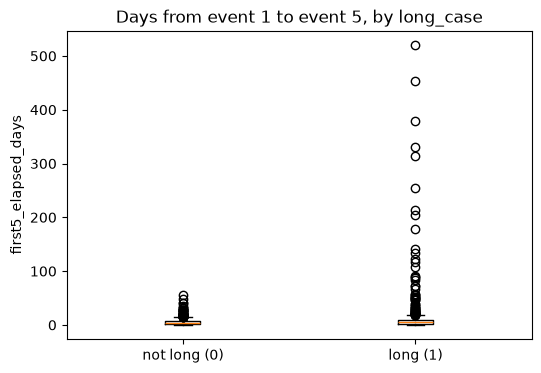

In [8]:
plt.figure(figsize=(6, 4))
plt.boxplot([early.loc[early["long_case"] == 0, "first5_elapsed_days"],
             early.loc[early["long_case"] == 1, "first5_elapsed_days"]])
plt.xticks([1, 2], ["not long (0)", "long (1)"])
plt.title("Days from event 1 to event 5, by long_case")
plt.ylabel("first5_elapsed_days")
plt.show()

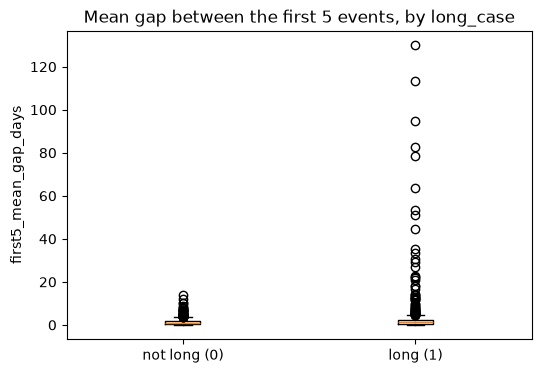

In [9]:
plt.figure(figsize=(6, 4))
plt.boxplot([early.loc[early["long_case"] == 0, "first5_mean_gap_days"],
             early.loc[early["long_case"] == 1, "first5_mean_gap_days"]])
plt.xticks([1, 2], ["not long (0)", "long (1)"])
plt.title("Mean gap between the first 5 events, by long_case")
plt.ylabel("first5_mean_gap_days")
plt.show()

## 10. Simple Correlation Check

Correlation of each early feature with the final `duration_days`. A weak individual correlation does not necessarily mean
a feature is useless in a model, because features can be useful in combination.

In [10]:
early[feature_columns + ["duration_days"]].corr()["duration_days"].drop("duration_days").round(2)

first5_elapsed_days           0.33
first5_unique_activities     -0.03
first5_unique_resources       0.19
first5_repeated_activities    0.03
first5_mean_gap_days          0.33
Name: duration_days, dtype: float64

## 11. Simple Classification Baseline (Logistic Regression)

A very simple, untuned Logistic Regression that uses only the five early features to predict `long_case`.
`stratify=y` keeps the same share of long cases in the training and test sets.

In [11]:
X = early[feature_columns]
y = early["long_case"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Training cases:", len(X_train), "| Test cases:", len(X_test))
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.2f}")
print(f"Precision: {precision_score(y_test, y_pred):.2f}")
print(f"Recall:    {recall_score(y_test, y_pred):.2f}")
print(f"F1:        {f1_score(y_test, y_pred):.2f}")

Training cases: 763 | Test cases: 191
Accuracy:  0.55
Precision: 0.60
Recall:    0.28
F1:        0.38


In [12]:
pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=["actual 0 (not long)", "actual 1 (long)"],
    columns=["predicted 0", "predicted 1"],
)

,predicted 0,predicted 1
actual 0 (not long),80,17
actual 1 (long),68,26


**Majority baseline:** always predict the most common class in the training set.

In [13]:
majority_class = y_train.mode()[0]
baseline_accuracy = (y_test == majority_class).mean()

print("Majority class in training set:", majority_class)
print(f"Majority baseline accuracy: {baseline_accuracy:.2f}")
print(f"Logistic Regression accuracy: {accuracy_score(y_test, y_pred):.2f}")

Majority class in training set: 0
Majority baseline accuracy: 0.51
Logistic Regression accuracy: 0.55


## 12. Interpretation

1. **Do early features differ between long and non-long cases?** Only partly. The *mean* time to reach the 5th event is much
   higher for long cases (15.67 vs 6.37 days), but the *median* is almost the same (5.38 vs 4.49 days). So most long cases
   start just like short cases; the difference comes from a minority of cases with a very slow start (the outliers in the
   boxplots). The activity features hardly vary: 951 of the 954 cases have 5 different activities among their first 5 events,
   so `first5_unique_activities` and `first5_repeated_activities` carry almost no information this early.
2. **Which early feature appears most informative?** `first5_elapsed_days` (correlation 0.33 with final duration), and
   `first5_mean_gap_days`, which is the same information divided by 4. `first5_unique_resources` is weaker (0.19).
   Part of the elapsed-time signal is automatic: 21 cases already needed more than 63 days to reach their 5th event,
   so they were long by definition.
3. **Does Logistic Regression beat the majority baseline?** Only slightly: accuracy 0.55 vs 0.51. It finds few long cases
   (recall 0.28: 26 of 94 long test cases), although when it does predict "long" it is right 60% of the time (precision 0.60).
4. **Is there evidence that early process behaviour contains predictive signal?** **Weak evidence.** A slow start is
   associated with a long case, but most long cases cannot be recognised from their first five events.
5. **Is the result strong enough for a final model?** **No.** A 4-percentage-point gain on 191 test cases is small and could
   partly be chance.
6. **What should be tested next?** Better early features, for example a later prediction point (more than 5 events, or a
   fixed number of days after the start) and *which* activities happened early, not only how many.

## 13. Important Limitation

This is still an **exploratory proof of concept**. The dataset comes from **one Dutch municipality** and not from SPAR or
Montenegro. The first-five-event cutoff is a **simple experiment** and may not be the final prediction point; because many
cases reach their 5th event within a few days, it is a very early and limited view of the case.

## 14. Next Step

The early signal is **weak**, so the next step is to **improve the early feature engineering before adding model
complexity**. Comparing Decision Tree, Random Forest and Gradient Boosting on these five features is unlikely to help much
while the features themselves contain so little information.